# 01 Data QA — PVDAQ system 9069 (Simon Solar Farm, GA)

Goal of Phase 1: decide whether 9069 is usable, on which period and with which sensors, and produce a clean dataset. Configuration: `configs/system_9069.yaml`.

Sections:
1. Data coverage and sensor availability (full period, point sampling)
2. Clock and time zone: per-file clock rules, conversion to UTC, acceptance test
3. Geometry and sensors on clear days: fixed vs tracker, orientation grid, inverter ratings, sensor agreement → station decision
4. Cleaning and QA report (duplicates, stuck values, irradiance outliers, daylight filter) — *to be added*

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Run from the project root so that `src` imports and relative paths in the config work.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import pandas as pd

from pv_loss_auditor import coverage as cv
from pv_loss_auditor.config import load_config
from pv_loss_auditor.plots import availability_heatmap

config = load_config("configs/system_9069.yaml")

## 1. Data coverage and sensor availability

**Method.** Point sampling instead of a full download: ~20 single-row reads per month per file via HTTP byte ranges (≈ 23 MB of traffic instead of ≈ 2.4 GB of CSV); each read returns a snapshot of all channels at one timestamp. Daylight = sun elevation > 15°, so that a 1-hour time-zone error cannot move a snapshot into the night. With ~9 daylight snapshots per month the availability estimate is accurate to about **±15 percentage points**.

Details: *valid* = not empty and not a logger placeholder (≤ −250, e.g. −297, −300). Gaps are found from time jumps between neighbouring snapshots; gaps shorter than ~3 days may be missed. Meter and irradiance files use stratified random offsets (a fixed step of ~25 h aliased with the daily cycle); electrical_ac and environment were sampled with a fixed step of ~32 h, which shifts the time of day by 8 h per snapshot and does not alias. All results below are read from the local cache (`data/processed/9069_coverage/`), no network access.

In [2]:
samples, gaps = cv.load_coverage(config)
table, n_daylight = cv.availability_table(samples, config)

months = pd.period_range("2016-02", "2023-11", freq="M")
table = table.reindex(columns=months)
table.index = [cv.short_label(c) for c in table.index]
n_daylight = n_daylight.reindex(months)
n_daylight.describe().round(1)

,electrical_ac,environment,irradiance,meter
count,90.0,89.0,91.0,78.0
mean,8.4,8.5,8.9,9.7
std,2.6,3.0,5.0,4.2
min,1.0,2.0,1.0,1.0
25%,7.0,7.0,4.5,7.0
50%,9.0,9.0,9.0,10.0
75%,10.0,11.0,13.0,12.0
max,14.0,15.0,24.0,20.0


Gaps longer than 1 day (no rows in the file):

In [3]:
gaps.sort_values(["last_before", "file"]).reset_index(drop=True).head(25)

,file,last_before,first_after,days
0,irradiance,2016-03-13 01:55:00,2016-03-15 11:45:00,2.4
1,meter,2016-04-28 07:15:00,2016-05-04 16:30:00,6.4
2,electrical_ac,2017-02-06 21:15:00,2017-05-13 07:30:00,95.4
3,environment,2017-02-06 21:15:00,2017-05-13 03:25:00,95.3
4,irradiance,2017-02-06 21:15:00,2017-05-13 03:25:00,95.3
5,meter,2017-02-06 21:15:00,2017-05-13 10:35:00,95.6
6,electrical_ac,2017-08-09 07:25:00,2017-08-18 21:00:00,9.6
7,environment,2017-08-09 07:25:00,2017-08-18 20:25:00,9.5
8,irradiance,2017-08-09 07:25:00,2017-08-18 20:25:00,9.5
9,meter,2017-08-09 07:25:00,2017-08-18 21:50:00,9.6


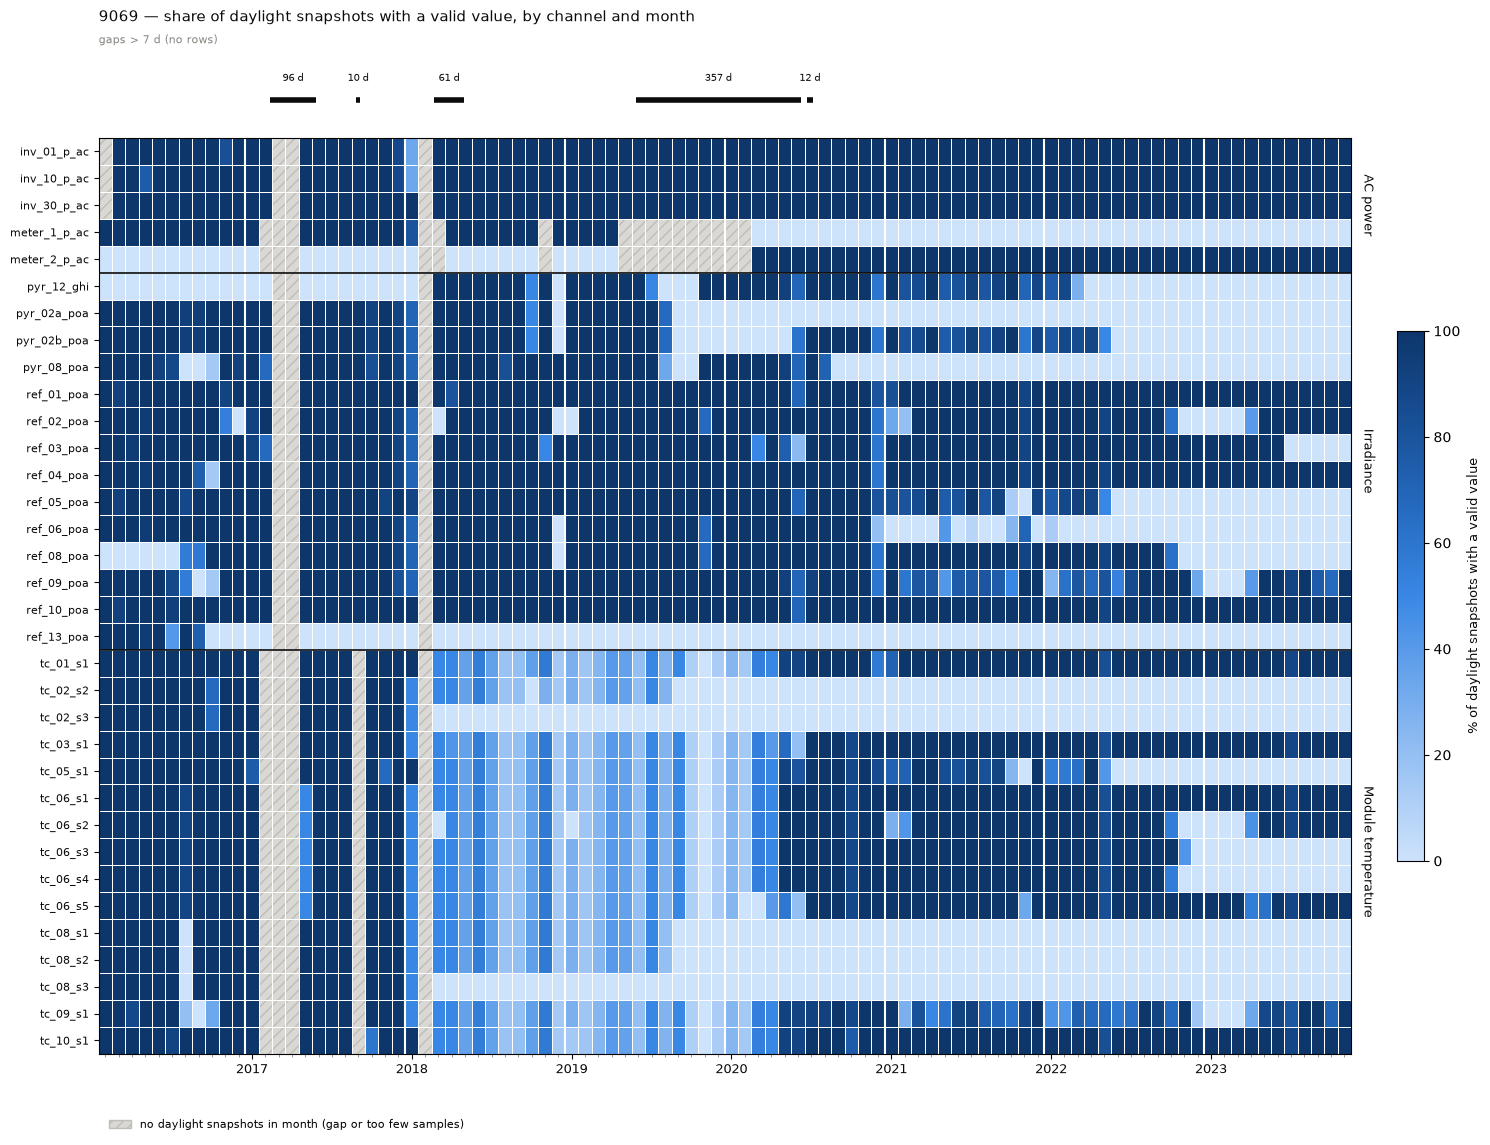

In [4]:
groups = [
    ("AC power", ["inv_01_p_ac", "inv_10_p_ac", "inv_30_p_ac", "meter_1_p_ac", "meter_2_p_ac"]),
    ("Irradiance", ["pyr_12_ghi"] + sorted(l for l in table.index if l.endswith("_poa"))),
    ("Module temperature", sorted(l for l in table.index if l.startswith("tc_"))),
]
fig = availability_heatmap(
    table, groups, gaps,
    title="9069 — share of daylight snapshots with a valid value, by channel and month",
)
Path("reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("reports/figures/9069_data_coverage.png", dpi=130, bbox_inches="tight")

Yearly mean availability (%), for a compact overview:

In [5]:
table.T.groupby(table.columns.year).mean().T.round(0)

,2016,2017,2018,2019,2020,2021,2022,2023
inv_01_p_ac,98.0,99.0,94.0,100.0,100.0,100.0,100.0,100.0
inv_10_p_ac,98.0,99.0,94.0,100.0,100.0,100.0,100.0,100.0
inv_30_p_ac,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
tc_01_s1,100.0,100.0,43.0,26.0,74.0,98.0,99.0,99.0
tc_02_s2,97.0,100.0,33.0,20.0,0.0,0.0,0.0,0.0
tc_02_s3,97.0,100.0,5.0,0.0,0.0,0.0,0.0,0.0
tc_03_s1,100.0,100.0,38.0,26.0,67.0,100.0,99.0,99.0
tc_05_s1,100.0,93.0,43.0,26.0,74.0,75.0,27.0,0.0
tc_06_s1,99.0,94.0,39.0,26.0,78.0,100.0,99.0,99.0
tc_06_s2,99.0,94.0,34.0,24.0,78.0,89.0,78.0,67.0


### Observations

- **Gaps common to all files:** 2017-02-06 → 2017-05-13 (95 d), 2017-08-09 → 2017-08-18 (10 d), 2018-01-26 → 2018-03-28 (60 d).
- **Meter:** meter 1 reports 2016-02 … 2019-04, then a 357-day gap in the meter file (2019-04-04 → 2020-03-26); from 2020-03 only meter 2 reports. Whether both are the same plant revenue meter is an assumption, to be verified by magnitude.
- **Inverters 01 / 10 / 30:** close to 100 % outside the common gaps.
- **Module temperature:** all thermocouples are intermittent from 2018-03 to 2020-04 (same pattern on every sensor → likely a logger-level problem); from 2020-05 thermocouples 01, 03, 06 s1 and 10 are ≥ 90 %. Thermocouples 02 and 08 are dead from 2020.
- **POA:** reference cells 01, 04 and 10 are ≥ 90 % in almost every month. Class-A pyranometers (02A, 02B, 08) stop between 2020 and 2022; GHI (pyranometer 12) is missing in 2016–2017 and mostly in 2022–2023.
- Irradiance is logged at 15-min steps in 2019 (found in step 0), hence fewer snapshots.

Choice of the analysis period: pending (see candidates).

## 2. Clock and time zone (analysis period 2020-05 … 2023-11)

Timestamps in the PVDAQ files are naive; the metadata gives only `timezone_code: 5`. This is checked first, before geometry, because a clock error looks like an azimuth error.

**Method.** For every day and every channel that follows the sun, the day's 5-min profile is correlated with clear-sky GHI (pvlib, Haurwitz model) shifted by candidate offsets from UTC−6 to UTC−3 in 5-min steps; the offset with the highest correlation *r* is the day's clock offset (label − UTC). Haurwitz needs only the sun position, and correlation ignores amplitude, so the same test works for irradiance and for AC power. Only clear days (*r* > 0.97) are used for conclusions. The night-time jumps in the timestamp axis are **not** used: they fall on the same dates in every file, while the data content of the files follows different rules (below).

**Candidate rules.** UTC−5 in winter and UTC−4 in summer, with the switch on US dates (2nd Sunday of March, 1st Sunday of November; `America/New_York`) or on EU dates (last Sunday of March and of October, 01:00 UTC) — the EU hypothesis came from the switch windows in the GHI data.

In [6]:
from pv_loss_auditor import timealign as ta
from pv_loss_auditor.plots import clock_offset_plot

lat, lon = config["system"]["latitude"], config["system"]["longitude"]
clk = config["clock"]


def channel(file, col):
    """One column of the analysis period, on raw naive labels (nothing converted yet)."""
    return ta.load_period(config, file, [col])[col]


# One sun-following channel per file (environment: module temperature, used in the test below).
ref = channel("irradiance", clk["reference_channel"])
ghi = channel("irradiance", "ghi_pyr12_wm2")
inv01 = channel("electrical_ac", "p_ac_inv01_kw")
meter2 = channel("meter", "p_ac_meter2_kw")
tmod = channel("environment", "t_mod_tc01s1_c")

channels = {"POA ref cell 01": ref, "GHI pyranometer 12": ghi,
            "AC inverter 01": inv01, "AC meter 2": meter2}
offsets = {name: ta.daily_clock_offset(s, lat, lon, min_r=clk["clear_day_min_r"])
           for name, s in channels.items()}
pd.Series({name: len(o) for name, o in offsets.items()}, name="clear days (r > 0.97)")

POA ref cell 01       315
GHI pyranometer 12     93
AC inverter 01        244
AC meter 2            328
Name: clear days (r > 0.97), dtype: int64

In [7]:
rules = ["America/New_York", ta.EU_DST_UTC5]
# Rows: channel; columns: number of clear days that contradict each rule (|detected - expected| > 0.5 h).
pd.DataFrame({name: ta.rule_mismatches(o, rules, min_r=clk["clear_day_min_r"])["mismatches"]
              for name, o in offsets.items()}).T.assign(clear_days=[len(o) for o in offsets.values()])

rule,America/New_York,eu_dst_utc-5,clear_days
POA ref cell 01,23,0,315
GHI pyranometer 12,2,0,93
AC inverter 01,0,14,244
AC meter 2,0,23,328


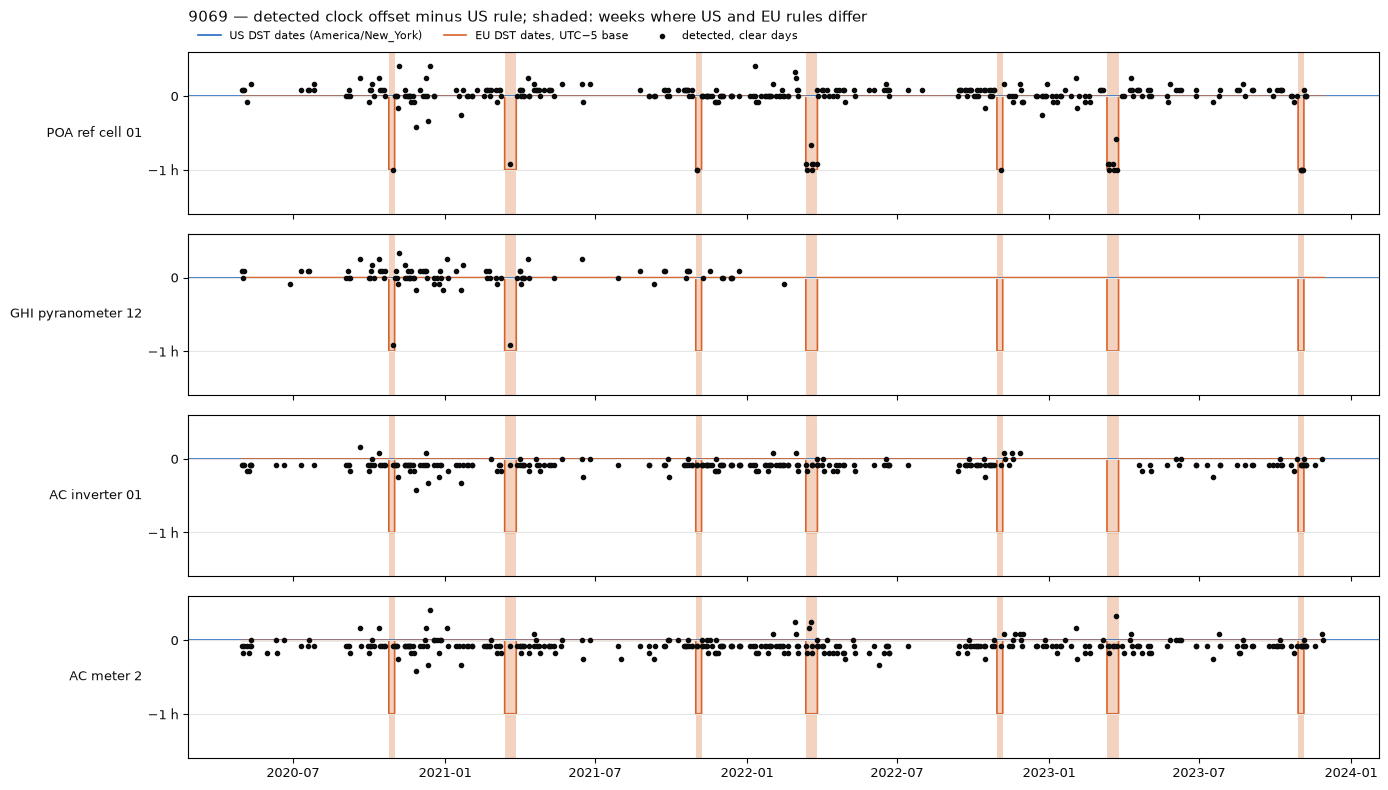

In [8]:
days = pd.date_range("2020-05-01", "2023-11-30", freq="D")
us = pd.Series(ta.expected_offset_h(days, "America/New_York").values, index=days)
eu = pd.Series(ta.expected_offset_h(days, ta.EU_DST_UTC5).values, index=days)
windows = [(a, b) for a, b in ta.rule_windows(range(2020, 2024)) if a >= days[0]]
fig = clock_offset_plot(
    offsets, base=("US DST dates (America/New_York)", us), other=("EU DST dates, UTC−5 base", eu),
    windows=windows,
    title="9069 — detected clock offset minus US rule; shaded: weeks where US and EU rules differ",
)
fig.savefig("reports/figures/9069_clock_offset.png", dpi=130, bbox_inches="tight")

**Acceptance test of the conversion.** The two rules give different answers only in the weeks between the US and EU switch dates (2 weeks in spring, 1 week in autumn). In those weeks, the lag between each channel and the reference cell is measured before conversion (raw labels) and after conversion to UTC with the per-file rules (`clock.rules` in the config). Pass = lag 0 after conversion in every window. Module temperature lags irradiance by 5–35 min because of thermal inertia; for it, the test is "same lag as in the control week", not "lag 0".

In [9]:
def to_utc_series(s, file):
    """Series on naive labels -> Series on UTC, with the clock rule of its file (config)."""
    out = s.copy()
    out.index = ta.to_utc(s.index, clk["rules"][file])
    return out[out.index.notna()]  # drops the skipped / repeated hour at a switch (night)


ref_utc = to_utc_series(ref, "irradiance")
others = {"AC inverter 01": (inv01, "electrical_ac"),
          "AC meter 2": (meter2, "meter"),
          "T module tc 01": (tmod, "environment")}
others_utc = {name: to_utc_series(s, file) for name, (s, file) in others.items()}

# Each window where the rules differ (from the plot cell), plus a control week before it
# (both rules agree there, so any lag in it is physical, not a clock effect).
checks = []
for a, b in windows:
    label = f"{a:%Y-%m-%d} to {b:%m-%d}"
    checks += [(label, "rules differ", a, b),
               (label, "control (week before)", a - pd.Timedelta(days=7), a - pd.Timedelta(days=1))]

rows = []
for label, kind, a, b in checks:
    end = b + pd.Timedelta("23h55min")
    # Same local days in UTC: shift by 5 h (exact to within the 1 h that is being tested).
    a_utc, end_utc = [(t + pd.Timedelta(hours=5)).tz_localize("UTC") for t in (a, end)]
    for name, (s, _) in others.items():
        lag_raw, _ = ta.lag_h(ref, s, a, end)
        lag_utc, r_utc = ta.lag_h(ref_utc, others_utc[name], a_utc, end_utc)
        rows.append({"window": label, "kind": kind, "channel": name,
                     "lag_raw_h": lag_raw, "lag_utc_h": lag_utc, "r": round(r_utc, 2)})
lags = pd.DataFrame(rows)
# NaN = no usable data in the window (inverter 01 reports 0 kW from late Feb to mid-Apr 2023).
lags.pivot_table(index=["window", "kind"], columns="channel",
                 values=["lag_raw_h", "lag_utc_h"], sort=False, dropna=False).round(2)

lag_raw_h             \
channel                                   AC inverter 01 AC meter 2   
window              kind                                              
2020-10-25 to 10-31 rules differ                    1.00        1.0   
                    control (week before)          -0.08        0.0   
2021-03-14 to 03-27 rules differ                    1.00        1.0   
                    control (week before)           0.00        0.0   
2021-10-31 to 11-06 rules differ                    1.00        1.0   
                    control (week before)           0.00        0.0   
2022-03-13 to 03-26 rules differ                    1.00        1.0   
                    control (week before)           0.00        0.0   
2022-10-30 to 11-05 rules differ                    1.00        1.0   
                    control (week before)           0.00        0.0   
2023-03-12 to 03-25 rules differ                     NaN        1.0   
                    control (week before)            NaN        0.0   
2023-10-29 to 11-04 rules differ                    1.00        1.0   
                    control (week before)           0.00        0.0   

                                                              lag_utc_h  \
channel                                   T module tc 01 AC inverter 01   
window              kind                                                  
2020-10-25 to 10-31 rules differ                    0.08           0.00   
                    control (week before)           0.08          -0.08   
2021-03-14 to 03-27 rules differ                    0.08           0.00   
                    control (week before)           0.50           0.00   
2021-10-31 to 11-06 rules differ                    0.17           0.00   
                    control (week before)           0.25           0.00   
2022-03-13 to 03-26 rules differ                    0.58           0.00   
                    control (week before)           0.08           0.00   
2022-10-30 to 11-05 rules differ                    0.08           0.00   
                    control (week before)           0.58           0.00   
2023-03-12 to 03-25 rules differ                    0.50            NaN   
                    control (week before)           0.58            NaN   
2023-10-29 to 11-04 rules differ                    0.58           0.00   
                    control (week before)           0.17           0.00   

                                                                     
channel                                   AC meter 2 T module tc 01  
window              kind                                             
2020-10-25 to 10-31 rules differ                 0.0           0.08  
                    control (week before)        0.0           0.08  
2021-03-14 to 03-27 rules differ                 0.0           0.08  
                    control (week before)        0.0           0.50  
2021-10-31 to 11-06 rules differ                 0.0           0.17  
                    control (week before)        0.0           0.25  
2022-03-13 to 03-26 rules differ                 0.0           0.58  
                    control (week before)        0.0           0.08  
2022-10-30 to 11-05 rules differ                 0.0           0.08  
                    control (week before)        0.0           0.58  
2023-03-12 to 03-25 rules differ                 0.0           0.50  
                    control (week before)        0.0           0.58  
2023-10-29 to 11-04 rules differ                 0.0           0.58  
                    control (week before)        0.0           0.17

### Observations — clock

- **The files do not share one clock.** All of them run at UTC−5 in winter and UTC−4 in summer, but:
  - **irradiance** (reference cell 01: 315 clear days, GHI: 93) switches on **EU dates** (last Sunday of March / October): 0 clear days contradict the EU rule, 23 (cell) contradict the US rule — all of them inside the shaded weeks;
  - **electrical_ac** (inverter 01: 244 clear days) and **meter** (meter 2: 328) switch on **US dates**: 0 contradict the US rule, 14 / 23 contradict the EU rule.
- **Environment** (module temperature, thermocouple 01) has the same lag to the reference cell inside the shaded weeks as in the control week before (5–35 min, thermal inertia), i.e. no 1 h jump: it runs on the irradiance clock. Inverter heatsink temperatures correlate too weakly with irradiance (r 0.3–0.45) to tell; they are marked unverified in the config and not used until checked.
- **Effect if ignored:** about 3 weeks a year (2 in spring, 1 in autumn) power would be shifted by 1 h against irradiance and module temperature — wrong PR on morning/evening hours and false anomalies.
- **Decision:** convert each file to UTC with its own rule (`clock.rules` in the config, `src/pv_loss_auditor/timealign.to_utc`). The skipped / repeated hour at each switch becomes NaT; it is always at night.
- **Acceptance test passed:** AC inverter 01 and meter 2 lag the reference cell by +1.0 h in every window before conversion and by 0.0 h after; in control weeks 0.0 both ways. Module temperature lag is unchanged by the conversion.
- The detected AC offset is systematically 5–10 min earlier than the irradiance offset (scatter just below 0 in the AC panels). Possible causes: interval labelling (start vs end of the 5-min interval) or the shape of the AC curve (clipping, inverter start-up). To check with the clear-day profiles in section 3.
- **Inverter 01 reports exactly 0 kW from late February to mid-April 2023** (~8 weeks) — a downtime candidate for Phase 3.
- The night-time jumps of the timestamp axis (1 h steps at 03:00 on US spring dates and at 21:00 before EU autumn dates, in every file) do not match the content of the files and are not used. They are probably an artefact of how the dataset was assembled.

## 3. Geometry and sensors (clear days, 2020-05 … 2022-03, all data in UTC)

Tests the NREL flag "Wrong mounting config identified": which mounting do the POA sensors see, and do the inverters behave like a fixed plant?

**Clear steps.** `pvlib.clearsky.detect_clearsky` (Reno & Hansen) on GHI of pyranometer 12, which exists only until 2022-03. It compares measured GHI with the Ineichen clear-sky curve in a moving window (mean, max, line length, variability, slope). The method was designed for 1-min data and a 10-min window; for 5-min data the window is 30 min (6 points) with `infer_limits=True`. A **clear day** has ≥ 90 % of its daylight steps (sun > 10°) flagged clear. For the POA fit only clear steps with sun > 15° are used.

**Models.** POA for the metadata geometry (fixed 20°/180°) and for a single-axis tracker (N–S axis, ±60°, backtracking, GCR 0.4), each from two inputs: measured GHI → Erbs → Perez (real sky, plus decomposition error), and clear-sky Ineichen → Perez (no decomposition error, valid on clear steps only). Measured POA = mean of reference cells 01 / 04 / 10. Metrics: nRMSE and MBE in % of the mean measured POA, R².

**Decision thresholds (agreed before the test).** Continue with 9069 if the fixed model beats the tracker, nRMSE ≤ 10 %, |MBE| ≤ 5 %, the clock offset is constant (section 2) and ≥ 2 POA sensors agree (r ≥ 0.98, within ±5 %). Stop and discuss if nRMSE is 10–15 %, the tracker fits better, or sensors differ by more than 10 %.

In [10]:
from pv_loss_auditor import geometry as geo
from pv_loss_auditor.plots import geometry_check_plot

gc = config["geometry_check"]
irr = ta.load_period(config, "irradiance", [gc["ghi_channel"], *gc["poa_channels"], *gc["compare_channels"]])
irr.index = ta.to_utc(irr.index, clk["rules"]["irradiance"])
# Regular 5-min grid (missing steps -> NaN): detect_clearsky works on a moving window of steps.
irr = irr[irr.index.notna()][: gc["ghi_until"]].asfreq("5min")

site = geo.Site(lat, lon, config["system"]["elevation_m"], irr.index)
ghi = irr[gc["ghi_channel"]]
clear = site.clear_points(ghi, gc["clearsky_window_min"])
days_clear = geo.clear_days(clear, site.daylight(gc["daylight_min_elevation_deg"]),
                            gc["clear_day_min_fraction"])

# Measured POA = mean of the reference cells available at each step (skips a missing cell).
measured = irr[gc["poa_channels"]].mean(axis=1)
fit_mask = clear & site.daylight(gc["fit_min_elevation_deg"])
print(f"clear steps used for the fit: {int(fit_mask.sum())}; clear days: {len(days_clear)} "
      f"({days_clear.min():%Y-%m-%d} … {days_clear.max():%Y-%m-%d})")

clear steps used for the fit: 19256; clear days: 61 (2020-05-01 … 2022-01-29)


In [11]:
mount, tr = config["mount"], config["mount"]["tracker_hypothesis"]
trk_tilt, trk_az = site.tracker_orientation(tr["axis_tilt_deg"], tr["axis_azimuth_deg"],
                                            tr["max_angle_deg"], tr["backtrack"], tr["gcr"])
fixed_label = f"fixed {mount['tilt_deg']}/{mount['azimuth_deg']}"
models = {}
for src_label, src in [("GHI -> Erbs -> Perez", ghi), ("clear-sky Ineichen -> Perez", None)]:
    models[(fixed_label, src_label)] = site.poa(mount["tilt_deg"], mount["azimuth_deg"], src, gc["albedo"])
    models[("tracker", src_label)] = site.poa(trk_tilt, trk_az, src, gc["albedo"])

pd.DataFrame({k: geo.fit_metrics(m, measured, fit_mask) for k, m in models.items()}).T.round(3)

,,n,nRMSE_pct,MBE_pct,R2
fixed 20/180,GHI -> Erbs -> Perez,19256.0,4.898,0.876,0.981
tracker,GHI -> Erbs -> Perez,19256.0,36.283,16.365,-0.029
fixed 20/180,clear-sky Ineichen -> Perez,19256.0,4.043,-0.558,0.987
tracker,clear-sky Ineichen -> Perez,19256.0,34.427,15.417,0.074


In [12]:
grid = geo.orientation_grid(site, measured, fit_mask, gc["grid_tilts_deg"], gc["grid_azimuths_deg"], ghi)
best = grid.stack().nsmallest(3).round(1)
print("best fixed orientations (tilt, azimuth): nRMSE %\n", best.to_string())

# Residual of the metadata geometry by local hour: a geometry error would be asymmetric
# (azimuth) or grow towards noon (tilt); a symmetric morning/evening excess points to AOI.
geo.residual_by_hour(models[("fixed 20/180", "GHI -> Erbs -> Perez")], measured, fit_mask).round(1).to_frame("model - measured, % of mean").T

best fixed orientations (tilt, azimuth): nRMSE %
 tilt_deg  azimuth_deg
25        180            4.6
20        180            4.9
30        180            6.3


,7,8,9,10,11,12,13,14,15,16,17,18,19
"model - measured, % of mean",8.5,5.9,2.0,0.3,-0.6,-1.4,-1.7,-0.9,0.2,2.6,4.1,6.3,6.9


In [13]:
ac = ta.load_period(config, "electrical_ac")
ac.index = ta.to_utc(ac.index, clk["rules"]["electrical_ac"])
ac = ac[ac.index.notna()]
meter = to_utc_series(meter2, "meter")

# Per inverter on clear days: equal energy = equal DC; peak max = clipping level = AC rating.
inv_summary = geo.clear_day_inverter_summary(ac, days_clear)
in_period = geo.local_day(ac.index).isin(days_clear)
meter_ratio = ac[in_period].clip(lower=0).sum().sum() / meter[geo.local_day(meter.index).isin(days_clear)].clip(lower=0).sum()
print(f"sum of 40 inverters / meter 2, clear days: {meter_ratio:.3f}")
print("energy_rel, inverters 01-20 vs 21-40 (median):",
      round(inv_summary["energy_rel"].iloc[:20].median(), 3), round(inv_summary["energy_rel"].iloc[20:].median(), 3))
inv_summary.describe().round(3)

sum of 40 inverters / meter 2, clear days: 1.022
energy_rel, inverters 01-20 vs 21-40 (median): 1.005 0.981


,peak_median_kw,peak_max_kw,energy_rel
count,40.000,40.000,40.000
mean,697.100,825.478,0.995
std,15.392,0.878,0.034
min,645.800,824.900,0.881
25%,689.000,825.000,0.977
50%,696.200,825.200,1.000
75%,707.975,825.525,1.019
max,728.300,830.000,1.049


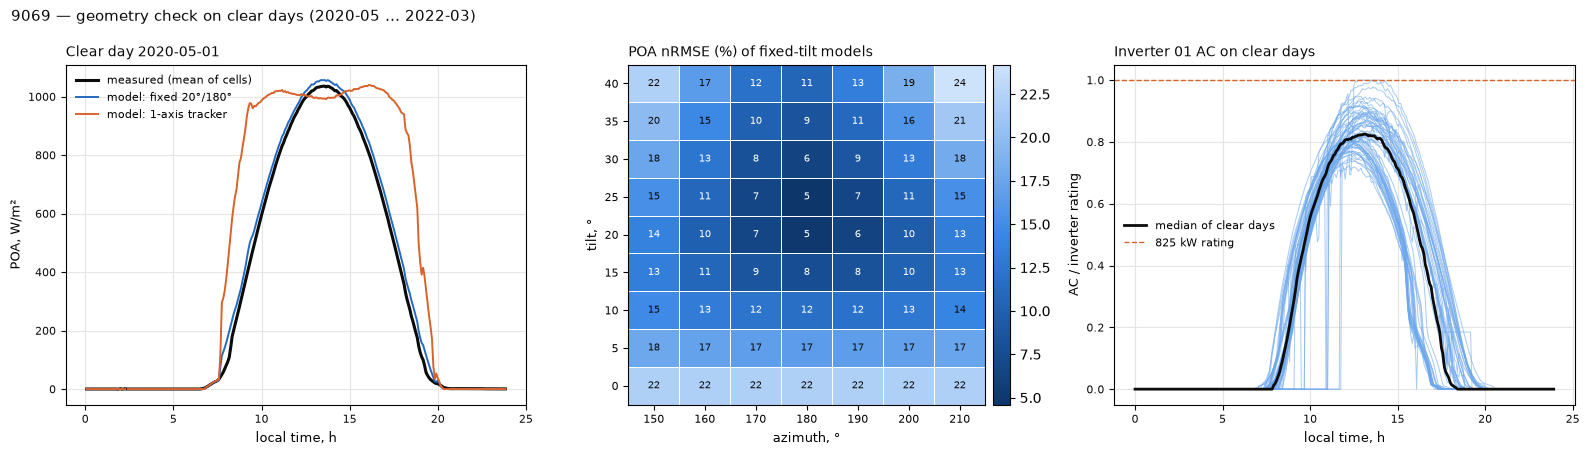

In [14]:
# Example day: the clear day with the highest measured POA energy.
day_of = geo.local_day(measured.index)
example = max(days_clear, key=lambda d: measured[day_of == d].sum())
sel = day_of == example
day_poa = pd.DataFrame({"measured": measured[sel],
                        "fixed": models[(fixed_label, "GHI -> Erbs -> Perez")][sel],
                        "tracker": models[("tracker", "GHI -> Erbs -> Perez")][sel]})
day_poa.index = day_poa.index.tz_convert(geo.LOCAL_TZ)

# Inverter 01 on every clear day, normalised by its AC rating, on local clock hours.
rating_kw = config["inverters"]["ac_kw"][0]["ac_kw"]
inv = ac["p_ac_inv01_kw"][geo.local_day(ac.index).isin(days_clear)]
t_local = inv.index.tz_convert(geo.LOCAL_TZ)
ac_profiles = pd.DataFrame({"value": inv.to_numpy() / rating_kw,
                            "day": t_local.normalize().tz_localize(None),
                            "hour": t_local.hour + t_local.minute / 60}
                           ).pivot_table(index="hour", columns="day", values="value")

fig = geometry_check_plot(day_poa, grid, ac_profiles, rating_kw,
                          title="9069 — geometry check on clear days (2020-05 … 2022-03)")
fig.savefig("reports/figures/9069_geometry_check.png", dpi=130, bbox_inches="tight")

In [15]:
sensors = irr[gc["poa_channels"] + gc["compare_channels"]]
# Ratio of sums of each sensor (rows) to each reference (columns) on clear steps.
# Around noon the angle of incidence is small, so cell-vs-pyranometer AOI differences vanish there.
noon = fit_mask & sensors.index.tz_convert(geo.LOCAL_TZ).hour.isin([11, 12, 13])
agreement = {}
for label, mask in [("all clear steps", fit_mask), ("clear steps 11-14 h local", noon)]:
    agreement[label] = pd.DataFrame({ref: geo.sensor_agreement(sensors, ref, mask)["ratio_to_reference"]
                                     for ref in sensors.columns})
r_min = min(geo.sensor_agreement(sensors, ref, fit_mask)["r"].min() for ref in sensors.columns)
print(f"lowest pairwise r on clear steps: {r_min:.4f}")
pd.concat(agreement).round(3)

lowest pairwise r on clear steps: 0.9913


poa_ref01_wm2  poa_ref04_wm2  \
                          sensor                                         
all clear steps           poa_pyr02b_wm2          1.102          1.045   
                          poa_ref01_wm2             NaN          0.949   
                          poa_ref04_wm2           1.054            NaN   
                          poa_ref10_wm2           1.035          0.982   
clear steps 11-14 h local poa_pyr02b_wm2          1.089          1.031   
                          poa_ref01_wm2             NaN          0.947   
                          poa_ref04_wm2           1.056            NaN   
                          poa_ref10_wm2           1.034          0.978   

                                          poa_ref10_wm2  poa_pyr02b_wm2  
                          sensor                                         
all clear steps           poa_pyr02b_wm2          1.062             NaN  
                          poa_ref01_wm2           0.966           0.908  
                          poa_ref04_wm2           1.019           0.957  
                          poa_ref10_wm2             NaN           0.942  
clear steps 11-14 h local poa_pyr02b_wm2          1.051             NaN  
                          poa_ref01_wm2           0.967           0.918  
                          poa_ref04_wm2           1.022           0.970  
                          poa_ref10_wm2             NaN           0.951

### Observations — geometry and sensors

- **Mounting: fixed 20°/180° confirmed.** On 19 256 clear steps (61 clear days) the metadata geometry gives nRMSE 4.9 %, MBE +0.9 %, R² 0.981 (measured GHI → Erbs → Perez) and 4.0 % / −0.6 % / 0.987 (clear-sky → Perez). The tracker hypothesis gives nRMSE 34–36 %, MBE +15–16 %, R² ≈ 0. The orientation grid has its minimum at 25°/180° (4.6 %), next to 20°/180° (4.9 %); ±10° of azimuth already costs 1.5–2 points. The NREL flag "Wrong mounting config identified" is **not supported** by the POA data.
- **Residual by hour** is symmetric: the model is 6–9 % above the cells at 7–8 h and 18–19 h and within ±2 % from 9 to 15 h. Symmetry rules out an azimuth error; the morning/evening excess is the typical angle-of-incidence (glass reflection) loss of reference cells, which the transposition model does not include.
- **Inverters behave like a fixed plant:** the clear-day AC curve is a bell; it reaches the 825 kW rating only on the brightest days (median clear-day peak 697 kW).
- **AC rating 825 kW holds for all 40 inverters:** the maximum clear-day peak of every inverter is 825–830 kW (clipping level). Plant AC = 40 × 825 = 33 000 kW, as assumed.
- **String metadata is wrong:** clear-day energy is equal across inverters (inverters 01–20: 1.005, 21–40: 0.981 of the median; all within 0.88–1.05), so DC is about equal per inverter, not 272 vs 68 strings. DC/AC ≈ 38 687 / 33 000 = 1.17.
- **Sum of inverters / meter 2 = 1.022** on clear days: about 2 % between inverter output and the meter, a plausible transformer + AC cable loss.
- **Sensor agreement:** every pair has r ≥ 0.991. Cells 04 and 10 agree within 2 % (1.8 %); **cell 01 reads 3.5–5.4 % below the other two cells** (the same at noon, so not an AOI effect). Pyranometer 02B reads 4.5 % above cell 04 and 6.2 % above cell 10 on all clear steps (3.1 % / 4.9 % at 11–14 h, where AOI effects are small), and **10.2 % above cell 01** (8.9 % at noon) — the only pair at the "differ by more than 10 %" threshold. Which sensors define POA for PR is a Phase 2 decision; cell 01 is the outlier.
- Some clear days show inverter 01 dropping to 0 in the middle of the day or holding a flat ~0.19 of rating in the evening: downtime / curtailment candidates for Phase 3.

**Decision against the agreed thresholds:** fixed beats tracker ✓, nRMSE 4.9 % ≤ 10 % ✓, |MBE| 0.9 % ≤ 5 % ✓, clock rules constant per file ✓ (section 2), ≥ 2 sensors agree (cells 04 and 10: r ≥ 0.99, 1.8 %) ✓. → **Continue with 9069.** One flag for review: pyranometer 02B vs cell 01 at 10.2 %.

## 4. Cleaning and QA report

**Principle: flag, do not delete.** All files go onto one 5-min UTC grid with their own clock rule (section 2). Values stay as measured; each problem gets a boolean column `flag_<test>__<channel>`, so every later phase chooses its own filter — PR needs clean irradiance, while downtime analysis must keep the zeros of a stopped inverter. Only two changes to values: logger placeholders (≤ −250) → NaN, and small negative night irradiance (sensor zero offset, −20…0 W/m²) → 0, flagged.

**Tests** (thresholds in `clean` of the config):
- *stale* — ≥ 6 identical consecutive values (30 min), pvanalytics `stale_values_diff`, only with sun > 5° (zeros at night are real). For AC power, exact 0 (inverter off) and the clipping plateau (≥ 98 % of 825 kW) are excluded: they are downtime and clipping, analysed in Phase 3.
- *range* — GHI: QCRAD physical limits (pvanalytics). POA: above 1.3 × clear-sky POA + 50 W/m² (cloud enhancement reaches about +30 %) or below −5 W/m² by day; any irradiance below −20 W/m² at night. AC: above 105 % of rating or below −10 kW per inverter. Temperature and wind: physical range (module −30…90 °C, ambient −30…50 °C, wind 0…60 m/s, direction 0…360°).
- *daylight* — `flag_daylight` = sun elevation > 0. The full day is kept, so that daily sums and night-time sensor offsets stay checkable. `sun_elevation_deg`, clear-sky GHI and clear-sky POA of the fixed plane are stored as columns for later filters.

Channels kept: GHI, cells 01 / 04 / 10, pyranometer 02B, thermocouples 01 / 06 s1 / 10, ambient temperature of stations 01 / 03 / 06 / 10, wind, 40 inverters, meter 2. Left out: inverter heatsink temperatures (clock not established) and thermocouple 03 s1 (implausible values for the whole period, see findings).

In [16]:
from pv_loss_auditor import data as clean

# Full run from the raw monthly parquet files (about 4 min; most of it is the stale-value test).
data, sentinels = clean.build_clean(config)
paths = clean.save_monthly(data, config["clean"]["out_dir"])
print(f"{len(paths)} monthly files, {data.shape[0]} steps x {data.shape[1]} columns "
      f"({sum(c.startswith('flag_') for c in data.columns)} flags), "
      f"{data.index.min():%Y-%m-%d %H:%M} … {data.index.max():%Y-%m-%d %H:%M} UTC")
data.iloc[:, :8].describe().round(1)

C:\Work\AI_ML_data portfolio\Portfolio tasks\pv-loss-auditor\src\clean.py:155: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  for month, part in data.groupby(data.index.to_period("M")):


43 monthly files, 376654 steps x 174 columns (116 flags), 2020-05-01 00:00 … 2023-11-29 19:45 UTC


,ghi_pyr12_wm2,poa_pyr02b_wm2,poa_ref01_wm2,poa_ref04_wm2,poa_ref10_wm2,t_mod_tc01s1_c,t_mod_tc06s1_c,t_mod_tc10s1_c
count,168877.0,175430.0,354293.0,361895.0,359887.0,354293.0,361898.0,359890.0
mean,184.6,215.1,198.8,209.0,207.2,23.0,22.9,21.4
std,272.4,318.7,295.9,309.9,304.6,14.8,15.3,13.9
min,0.0,-181.0,-2.0,0.0,0.0,-15.0,-15.3,-14.7
25%,0.0,2.0,0.0,3.0,2.0,12.5,12.3,11.4
50%,5.4,6.0,9.0,10.0,11.0,21.4,21.1,20.3
75%,314.6,358.0,331.0,346.0,344.0,32.1,32.0,29.5
max,1276.8,1335.0,1248.0,1268.0,1252.0,69.5,68.4,64.7


In [17]:
# % of daylight steps with a value / with each flag (night_zeroed: % of night steps).
# The 40 inverters are folded into two rows: median inverter and worst inverter.
clean.compact_summary(clean.flag_summary(data)).round(2)

,valid_daylight_pct,stale_pct,range_pct,night_zeroed_pct
channel,,,,
ghi_pyr12_wm2,44.96,0.00,0.00,0.00
poa_pyr02b_wm2,46.68,0.02,0.24,1.91
poa_ref01_wm2,95.94,0.03,0.03,51.71
poa_ref04_wm2,97.39,0.07,0.06,1.86
poa_ref10_wm2,97.15,0.03,0.07,0.10
t_mod_tc01s1_c,95.94,0.29,0.00,NaN
t_mod_tc06s1_c,97.39,2.29,0.00,NaN
t_mod_tc10s1_c,97.15,2.18,0.00,NaN
t_amb_ws01s1_c,95.94,3.86,0.00,NaN


C:\Work\AI_ML_data portfolio\Portfolio tasks\pv-loss-auditor\src\clean.py:207: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  out[ch] = 100 * good.groupby(good.index.to_period("M")).mean()


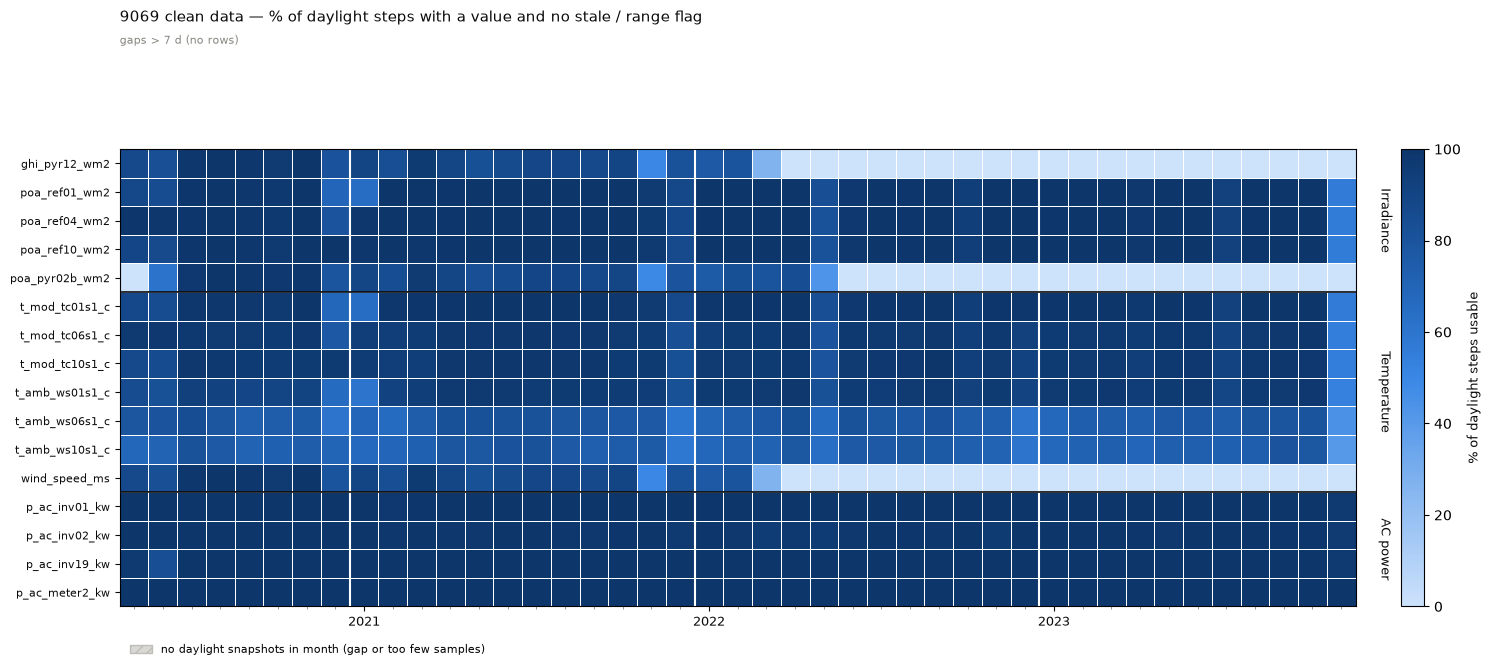

In [18]:
key_channels = {
    "Irradiance": ["ghi_pyr12_wm2", "poa_ref01_wm2", "poa_ref04_wm2", "poa_ref10_wm2", "poa_pyr02b_wm2"],
    "Temperature": ["t_mod_tc01s1_c", "t_mod_tc06s1_c", "t_mod_tc10s1_c",
                    "t_amb_ws01s1_c", "t_amb_ws06s1_c", "t_amb_ws10s1_c", "wind_speed_ms"],
    "AC power": ["p_ac_inv01_kw", "p_ac_inv02_kw", "p_ac_inv19_kw", "p_ac_meter2_kw"],
}
usable = clean.monthly_valid(data, [c for group in key_channels.values() for c in group]).T
fig = availability_heatmap(usable, list(key_channels.items()),
                           title="9069 clean data — % of daylight steps with a value and no stale / range flag")
fig.axes[-1].set_ylabel("% of daylight steps usable", fontsize=9)  # colorbar label: not 'snapshots' here
fig.savefig("reports/figures/9069_clean_usable.png", dpi=130, bbox_inches="tight")

In [19]:
findings = """\
- **Thermocouple 03 s1 is not a module temperature for the whole period:** monthly median 50–80 °C
  while thermocouple 01 reads 6–28 °C, about 45 °C at night, peaks up to 1138 °C, stuck at 1138
  from 2023-07. Excluded from the clean dataset. Its "96–99 % valid" in the coverage map (section 1)
  only meant "no placeholder"; that test did not check plausibility.
  → Module temperature from thermocouples 01 / 06 s1 / 10.
- **Ambient temperature, stations 03, 06 and 10:** 20–27 % of daylight steps sit in runs of ≥ 6
  identical values in every year, at 0.1 °C resolution: the logger holds the last value.
  Station 01: 3–7 %. → Use station 01 for ambient temperature.
- **Frozen inverter readings:** inverters 02, 19–22, 25, 26 hold arbitrary values (e.g. 77, 248,
  591 kW) for ≥ 30 min on 28–82 days each (0.4–0.7 % of daylight). Communication / logger freezes,
  not curtailment (the held level differs every time).
- **Pyranometer 02B:** all 9 848 logger placeholders of the period; out of range by day and down
  to −181 W/m² at night.
- **Wind:** values on 45 % of daylight steps only; 3276.7 (16-bit overflow, 32767 / 10) appears as
  a placeholder and is flagged out of range.
- **Reference cells:** out of range below 0.1 %. Night zero offset: cell 01 median 0 W/m² (negative
  on 52 % of night steps, set to 0), cell 04 about +3 W/m². Neither explains the 3–5 % daytime
  deficit of cell 01 (section 3).
- **GHI (pyranometer 12):** no range or stale flags; exists until 2022-03 only.
- **Not flagged on purpose:** inverter 01 at exactly 0 kW from late February to mid-April 2023
  (downtime, a real loss for Phase 3) and clipping at 825 kW.
"""
report = clean.write_report(data, sentinels, config, config["clean"]["report"], findings)
print("written:", report)

written: reports/9069_qa_report.md


C:\Work\AI_ML_data portfolio\Portfolio tasks\pv-loss-auditor\src\clean.py:207: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  out[ch] = 100 * good.groupby(good.index.to_period("M")).mean()


### Observations — cleaning

- Clean dataset: 43 months, 5-min UTC grid, written to `data/processed/9069/` (one parquet per UTC month, not in git); QA report: `reports/9069_qa_report.md`.
- Flags were checked by looking at what they catch, not only at their counts (findings in the report). Every large flag share is a real data problem (held logger values, frozen inverter readings), not a false alarm on a slowly changing signal.
- **Lesson:** the first run kept thermocouple 03 although it is implausible for the whole period — the coverage map and the stale test cannot see a sensor that reports wrong values that change. `describe()` of the clean data exposed it; a physical-range test for temperature and wind was added, and the channel was excluded.
- Consequences for Phase 2: POA from cells 04 / 10 (cell 01 reads low, section 3); module temperature from thermocouples 01 / 06 s1 / 10; ambient temperature from station 01; wind is available for less than half of the period.
- Phase 1 complete. Next: Phase 2 — expected yield model and KPIs.